In [5]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.interpolate import interp1d

In [21]:
rx_300m_2_long_etas=np.load('rx_300m_day_2_long_etas.npy')
rx_300m_2_long_argA=np.load('rx_300m_day_2_long_argA.npy')

In [16]:
rx_300m_4_etas=np.load('rx_300m_day_4_etas.npy')*100
rx_300m_4_argA=np.load('rx_300m_day_4_argA.npy')

In [25]:
frames=[]
for i in range(len(rx_300m_2_long_etas)):
    frames.append(i)

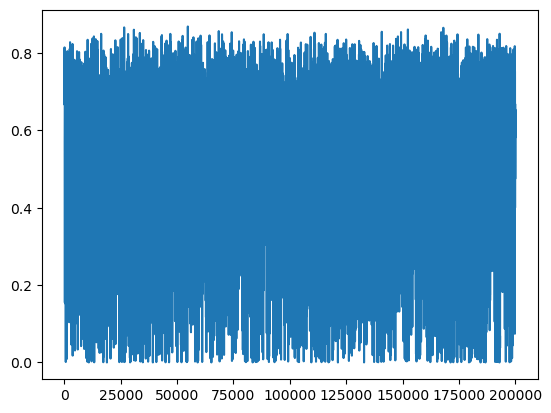

In [49]:
plt.plot(frames,rx_300m_2_long_etas)

In [41]:
power_mean=np.mean(rx_300m_2_long_etas)

In [51]:
power_mean

0.5086441046906451

In [55]:
power_fibre=107*(10**(-6))

In [57]:
power_fibre

0.000107

In [63]:
power_factor

0.00021036319700407593

In [61]:
power_factor=power_fibre/power_mean

In [65]:
powers=rx_300m_2_long_etas*power_factor

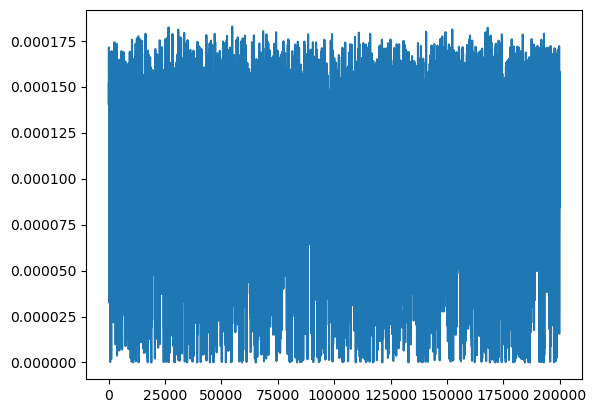

In [73]:
plt.plot(frames,powers)

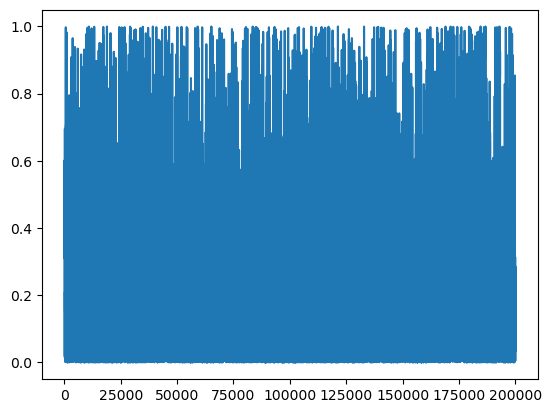

In [77]:
plt.plot(frames,powers_diff/power_fibre)

In [71]:
powers_diff=np.sqrt((powers-power_fibre)**2)

In [109]:
def power_diff_db(power_array):
    """
    Compute power difference in dB relative to the mean power.

    Parameters
    ----------
    power_array : array-like
        Optical power values in linear units (e.g., W or mW)

    Returns
    -------
    np.ndarray
        Power difference in dB for each sample relative to the mean
    """
    power_array = np.asarray(power_array)

    if np.any(power_array <= 0):
        raise ValueError("All power values must be positive to compute dB.")

    mean_power = np.mean(power_array)
    return 10 * np.log10(power_array / mean_power)


In [111]:
# Example usage
if __name__ == "__main__":
    powersdb=plot_power_diff_db(powers)

In [103]:
powersdb

array([1.52142414, 1.48344814, 1.44505611, ..., 0.63884732, 0.61204354,
       0.59009373])

In [115]:
def convert_to_diff_db(etas,power_fibre):
    power_mean=np.mean(etas)
    power_factor=power_fibre/power_mean
    power_array=etas*power_factor
    power_array = np.asarray(power_array)

    if np.any(power_array <= 0):
        raise ValueError("All power values must be positive to compute dB.")

    mean_power = np.mean(power_array)
    return 10 * np.log10(power_array / mean_power)

In [121]:
powersdbtest=convert_to_diff_db(rx_300m_2_long_etas,107)

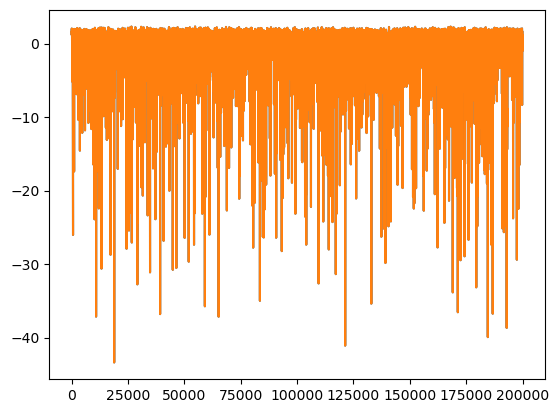

In [123]:
plt.plot(frames,powersdb)
plt.plot(frames,powersdbtest)

In [107]:
np.save('day_long_pdiff_db.npy', powersdb)

In [3]:
vs2=np.linspace(0,5,2000)

In [4]:
vs2

array([0.00000000e+00, 2.50125063e-03, 5.00250125e-03, ...,
       4.99499750e+00, 4.99749875e+00, 5.00000000e+00])

In [13]:
vsfixed = np.load('vsfixed.npy')
psfixed = np.load('psfixed.npy')
vs = np.load('vs.npy')
psnorm=100*psfixed/max(psfixed)

FileNotFoundError: [Errno 2] No such file or directory: 'vsfixed.npy'

In [6]:
attenuation_to_voltage = interp1d(psnorm, vs, bounds_error=False, fill_value="extrapolate")

In [7]:
corresponding_voltages_2 = attenuation_to_voltage(rx_300m_2_etas)

In [8]:
corresponding_voltages

NameError: name 'corresponding_voltages' is not defined

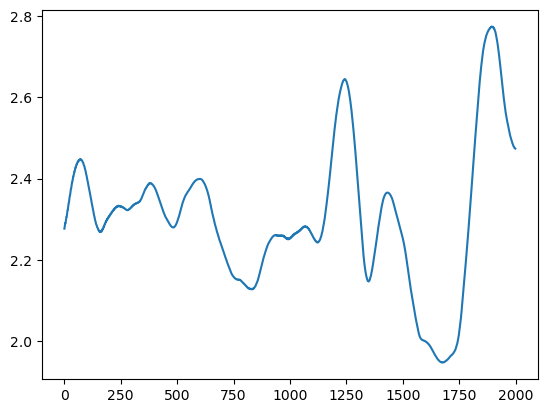

In [11]:
plt.plot(frames,corresponding_voltages_2)

In [12]:
np.save('day_2_voltages.npy',corresponding_voltages_2)

C:\Users\rr1184\AppData\Local\Temp\ipykernel_852\1794453148.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


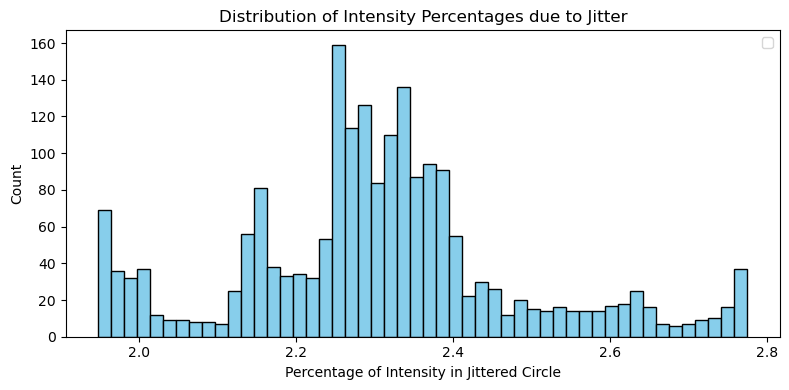

Mean intensity: 2.3047%
Standard deviation: ±0.1781%


In [14]:
intensity_percentages = np.array(corresponding_voltages_2)
mean_percentage = np.mean(intensity_percentages)
std_percentage = np.std(intensity_percentages)

plt.figure(figsize=(8, 4))
plt.hist(intensity_percentages, bins=50, color='skyblue', edgecolor='black')
plt.title("Distribution of Intensity Percentages due to Jitter")
plt.xlabel("Percentage of Intensity in Jittered Circle")
plt.ylabel("Count")
#plt.axvline(mean_percentage, color='red', linestyle='--', label=f"Mean: {mean_percentage:.2f}%")
#plt.axvline(mean_percentage + std_percentage, color='green', linestyle='--', label=f"+1σ: {mean_percentage + std_percentage:.2f}%")
#plt.axvline(mean_percentage - std_percentage, color='green', linestyle='--', label=f"-1σ: {mean_percentage - std_percentage:.2f}%")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Mean intensity: {mean_percentage:.4f}%")
print(f"Standard deviation: ±{std_percentage:.4f}%")

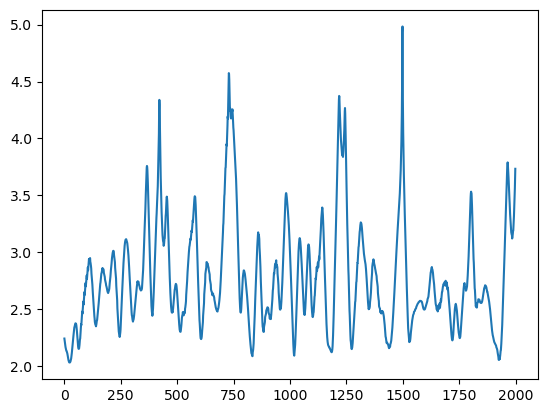

In [17]:
corresponding_voltages_3 = attenuation_to_voltage(rx_300m_3_etas)
plt.plot(frames,corresponding_voltages_3)

C:\Users\rr1184\AppData\Local\Temp\ipykernel_852\1514128960.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


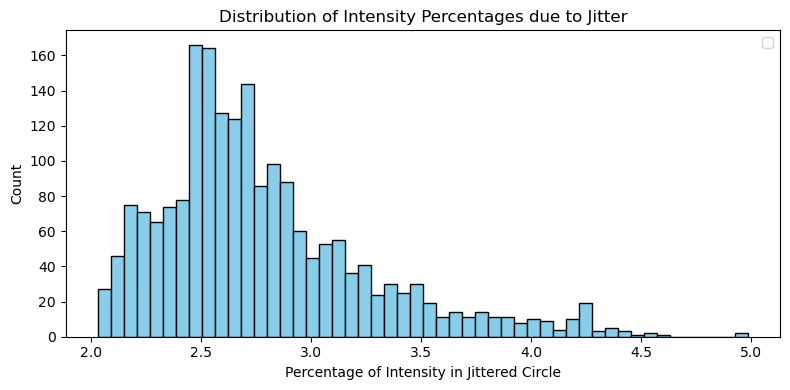

Mean intensity: 2.7779%
Standard deviation: ±0.4805%


In [18]:
intensity_percentages = np.array(corresponding_voltages_3)
mean_percentage = np.mean(intensity_percentages)
std_percentage = np.std(intensity_percentages)

plt.figure(figsize=(8, 4))
plt.hist(intensity_percentages, bins=50, color='skyblue', edgecolor='black')
plt.title("Distribution of Intensity Percentages due to Jitter")
plt.xlabel("Percentage of Intensity in Jittered Circle")
plt.ylabel("Count")
#plt.axvline(mean_percentage, color='red', linestyle='--', label=f"Mean: {mean_percentage:.2f}%")
#plt.axvline(mean_percentage + std_percentage, color='green', linestyle='--', label=f"+1σ: {mean_percentage + std_percentage:.2f}%")
#plt.axvline(mean_percentage - std_percentage, color='green', linestyle='--', label=f"-1σ: {mean_percentage - std_percentage:.2f}%")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Mean intensity: {mean_percentage:.4f}%")
print(f"Standard deviation: ±{std_percentage:.4f}%")

In [19]:
np.save('day_3_voltages.npy',corresponding_voltages_3)

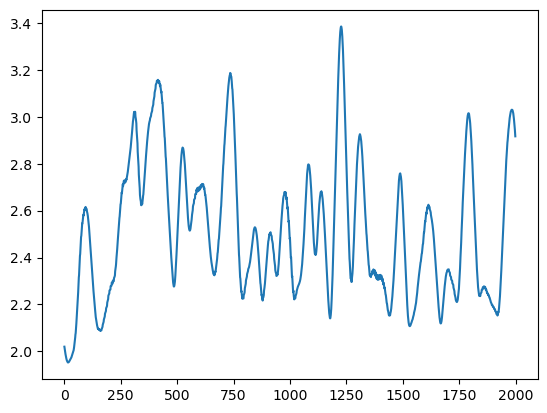

In [20]:
corresponding_voltages_4 = attenuation_to_voltage(rx_300m_4_etas)
plt.plot(frames,corresponding_voltages_4)

C:\Users\rr1184\AppData\Local\Temp\ipykernel_852\4126762800.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


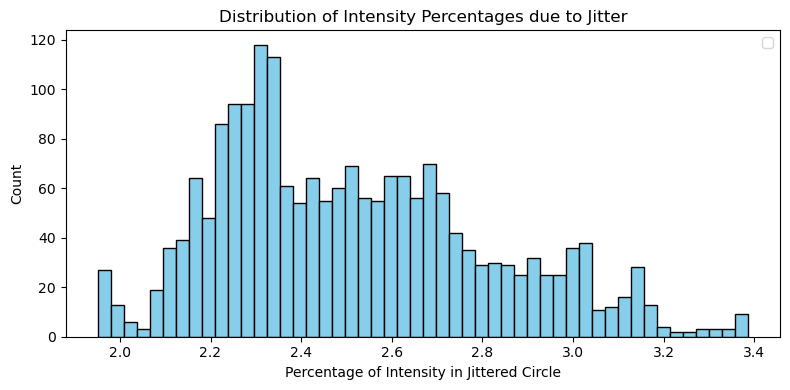

Mean intensity: 2.5150%
Standard deviation: ±0.2943%


In [21]:
intensity_percentages = np.array(corresponding_voltages_4)
mean_percentage = np.mean(intensity_percentages)
std_percentage = np.std(intensity_percentages)

plt.figure(figsize=(8, 4))
plt.hist(intensity_percentages, bins=50, color='skyblue', edgecolor='black')
plt.title("Distribution of Intensity Percentages due to Jitter")
plt.xlabel("Percentage of Intensity in Jittered Circle")
plt.ylabel("Count")
#plt.axvline(mean_percentage, color='red', linestyle='--', label=f"Mean: {mean_percentage:.2f}%")
#plt.axvline(mean_percentage + std_percentage, color='green', linestyle='--', label=f"+1σ: {mean_percentage + std_percentage:.2f}%")
#plt.axvline(mean_percentage - std_percentage, color='green', linestyle='--', label=f"-1σ: {mean_percentage - std_percentage:.2f}%")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Mean intensity: {mean_percentage:.4f}%")
print(f"Standard deviation: ±{std_percentage:.4f}%")

In [22]:
np.save('day_4_voltages.npy',corresponding_voltages_4)